# Measurement noise and the information floor

I want to understand the minimum number of bits needed to model a dataset perfectly. Here the dataset is the aqueous solubility of compounds (AqSolDB). This notebook establishes a floor: how many bits a measurement actually carries about a compound's solubility. The later notebooks use it as a yardstick, to see how close a model gets to the floor and to measure the rate we pay in bits going from a chemical representation to that limit.

To do this we need to determine how many values we need to represent. For a discrete case, we need to know the number of classes and the frequency of each class. The worst case, when every class is equally likely, is $\log_2 K$ bits: to pick one of four classes, a first yes/no question rules out two of them and a second question rules out one more.

We can use the Shannon entropy to determine the average number of bits:

$$H = -\sum_{k=1}^{K} p_k \log_2 p_k$$

Imagine we have the four classes but one class is 90%.

| class id | probability (%) |
|---:|---:|
| 1 | 90 |
| 2 | 5 |
| 3 | 4 |
| 4 | 1 |

On average we will need 0.6051 bits.

For continuous values we need to make this determination slightly differently. What matters is how spread out the values are compared with how precisely each one is measured. If all the values are clustered at the same spot there is little to learn: we simply assign everything the same value. If repeated measurements of the same compound scatter as widely as the values themselves, the data can't tell compounds apart at all. The more widely separated the compounds are relative to the measurement noise, the more levels of solubility the data can distinguish:

$$\text{bits} = \frac{1}{2}\log_2\left(\frac{\operatorname{Var}(Y)}{\operatorname{Var}(\text{noise})}\right)$$

where $\operatorname{Var}(Y)$ is the variance in the values across all samples and

$$\operatorname{Var}(\text{noise}) = \frac{\sum_{i}\sum_{j}\left(y_{ij} - \bar{y}_i\right)^2}{\text{total measurements} - \text{number of samples}}$$

with $y_{ij}$ the $j$-th measurement of sample $i$ and $\bar{y}_i$ the mean of that sample's measurements. The formula also assumes the noise is Gaussian with a single variance; it frames the question, and a later section replaces it with a computation that assumes no family once the noise has actually been isolated.

Since we want to model a continuous value, we pursue the second option. $\operatorname{Var}(Y)$ comes straight from the data, but $\operatorname{Var}(\text{noise})$ needs compounds measured more than once, and only works if those repeats are independent measurements — which first requires deciding what "the same compound" means. So the notebook runs in five steps:

1. Load the nine AqSolDB source files.
2. Decide what counts as the same compound, so that "repeated values" is a definition we chose and tested rather than an accident of how each source drew its structures: differences of representation are merged, differences of substance are kept apart, and the costliest ruling is tested against the data.
3. Find the compounds with repeated values, and check whether the differences between repeats look like measurement noise, and whether they depend on which sources the values come from.
4. Locate, from that evidence, the band where copies end, collapse each compound's copies into independent votes, and flag votes that can only be gross errors.
5. Estimate the remaining genuine noise without assuming a family, recompute the floor as a band, and hand one row per independent measurement to [02_tiers.ipynb](02_tiers.ipynb).

Let's start by getting a look at the data itself.

In [1]:
from pathlib import Path

import pandas as pd
from rdkit import Chem, RDLogger

RDLogger.DisableLog("rdApp.warning")  # AqSolDB's [H+]/hydride fragments warn on every parse

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TARGET = "Solubility"  # LogS, mol/L

# The nine unmerged AqSolDB source sets (scripts/fetch_aqsoldb.py): one row per reported value. The curated AqSolDB
# keeps one value per compound, which hides the repeated measurements Var(noise) needs.
src = pd.concat(
    [pd.read_csv(f).assign(source=f.stem[-1]) for f in sorted((ROOT / "data" / "aqsoldb_sources").glob("dataset-*.csv"))],
    ignore_index=True,
)

bad_smiles = src[src["SMILES"].map(lambda s: Chem.MolFromSmiles(s) is None)]
missing_target = src[src[TARGET].isna()]

# Two pyridine N-oxides are written with impossible charges ([NH++]/[CH-]); RDKit rejects them, so drop them.
# Neither compound appears in any other source, so no replicate is lost.
assert len(bad_smiles) == 2, f"{len(bad_smiles)} invalid SMILES (expected 2):\n{bad_smiles[['ID', 'SMILES']]}"
assert missing_target.empty, f"{len(missing_target)} rows missing {TARGET}"
src = src.drop(bad_smiles.index).reset_index(drop=True)
print(
    f"{len(src)} values: dropped {len(bad_smiles)} unparseable SMILES "
    f"({', '.join(bad_smiles['ID'])}), all have a measured value"
)

[14:11:17] Explicit valence for atom # 5 N, 4, is greater than permitted
[14:11:17] Explicit valence for atom # 5 N, 4, is greater than permitted


19793 values: dropped 2 unparseable SMILES (B-1579, B-1866), all have a measured value


## What counts as the same compound

Var(noise) comes from compounds with repeated values, so everything downstream depends on what "the same compound" means — and the nine sources write the same chemistry in different ways. Each way two structures can differ is a decision. The rule we apply: **merge differences of representation** — the same sample written two ways, which cannot change what was measured — and **keep differences of substance** — a different solid or species in the vial, which can. Merging too little hides replicate disagreements (and copies) behind an inflated compound count; merging too much manufactures "noise" that is really two different compounds.

| difference between two structures | ruling | reason |
|---|---|---|
| atom order, aromatic form, charge-separated groups | merge | the same molecule written differently; InChI normalizes these |
| isotopes | merge | isotopic substitution shifts solubility far below the noise scale (1 row: (²H)chloroform) |
| bare ion vs neutral form | merge | a lone charged fragment with no counterion is not a species a vial can hold; it is a drawing of the neutral compound's (or one of its salts') measurement |
| tautomers | merge, every merge reviewed below | in water tautomers interconvert far faster than any solubility measurement, so the measured value belongs to the equilibrating compound, not to the tautomer drawn |
| enantiomers | merge | mirror-image crystals have identical lattice energies, so in an achiral solvent their solubilities are identical |
| diastereomers, E/Z isomers | keep separate | genuinely different compounds: maleic and fumaric acid differ by ~2 logS |
| specified vs unspecified stereocentres | keep separate, ruling tested below | an unmarked structure is ambiguous between a careless drawing, unknown stereochemistry and a racemate — and a racemic crystal is a different solid with its own solubility |
| salts | keep separate | different solids whose solubilities differ chemically (AgCN, KCN, HCN), not by noise; this also bounds the bare-ion rule — compounds differing by H⁺ *across salts* (NaHS vs Na₂S) stay separate |
| hydrates | keep separate | anhydrous compound and hydrate are different solids; the explicit water fragment must survive |
| solid form: polymorph, racemate vs enantiopure, amorphous | nothing to key on | the same structure can label different crystals; surveyed polymorph pairs mostly differ by < 2× in solubility (≲ 0.3 logS), and that variation is a real, irreducible part of Var(noise) |

Keys are regenerated from each row's SMILES and the merges applied in stages, so the table below shows what each ruling is worth in compounds and replicate pairs.

In [2]:
import re

from rdkit.Chem.MolStandardize import rdMolStandardize

RDLogger.DisableLog("rdApp.info")  # the standardizer logs every transform it applies

uncharger = rdMolStandardize.Uncharger()
# The tautomer canonicalizer must not touch stereo: its default strips stereocentres near tautomeric sites, which
# would merge diastereomers against the ruling above (fructose with sorbose, tartaric with meso-tartaric acid) and
# specified structures with unspecified ones ((S)-naproxen with naproxen).
taut_params = rdMolStandardize.CleanupParameters()
taut_params.tautomerRemoveSp3Stereo = False
taut_params.tautomerRemoveBondStereo = False
tautomers = rdMolStandardize.TautomerEnumerator(taut_params)


def representation_merges(m: Chem.Mol) -> Chem.Mol:
    """Isotopes stripped; a bare ion (one fragment, net charge) neutralized. Salts and hydrates pass untouched."""
    m = Chem.Mol(m)
    for atom in m.GetAtoms():
        atom.SetIsotope(0)
    if len(Chem.GetMolFrags(m)) == 1 and Chem.GetFormalCharge(m) != 0:
        m = uncharger.uncharge(m)
    return m


def mirror(inchi: str) -> str:
    """The full mirror image: every /m parity flipped. Enantiomers, and only they, share min(inchi, mirror(inchi))."""
    return re.sub(r"/m([01.]+)", lambda g: "/m" + g.group(1).translate(str.maketrans("01", "10")), inchi)


failed: list[int] = []


def canonical_tautomer(i: int, m: Chem.Mol) -> Chem.Mol:
    try:
        return tautomers.Canonicalize(m)
    except Exception:
        failed.append(i)
        return m


mols = [Chem.MolFromSmiles(s) for s in src["SMILES"]]
plain = [representation_merges(m) for m in mols]
RDLogger.DisableLog("rdApp.error")  # the enumerator probes kekulization variants and logs every failed attempt
canonical = [canonical_tautomer(i, m) for i, m in enumerate(plain)]  # the slow stage: a couple of minutes
RDLogger.EnableLog("rdApp.error")
assert not failed, f"tautomer canonicalization failed for rows {failed[:5]}"

keys = pd.DataFrame(
    {
        "as written (InChIKey)": [Chem.MolToInchiKey(m) for m in mols],
        "+ isotopes, bare ions": [Chem.MolToInchiKey(m) for m in plain],
        "+ tautomers": [Chem.MolToInchiKey(m) for m in canonical],
        "+ enantiomers": [Chem.InchiToInchiKey(min(i, mirror(i))) for i in (Chem.MolToInchi(m) for m in canonical)],
    },
    index=src.index,
)

fragments = src["SMILES"].str.split(".")
print(
    f"merged: {sum(any(a.GetIsotope() for a in m.GetAtoms()) for m in mols)} isotopic rows, "
    f"{sum(len(Chem.GetMolFrags(m)) == 1 and Chem.GetFormalCharge(m) != 0 for m in mols)} bare-ion rows; "
    f"kept separate: {(fragments.map(len) > 1).sum()} multi-fragment rows (salts), "
    f"{fragments.map(lambda fs: any(f in ('O', '[OH2]', '[H]O[H]') for f in fs)).sum()} of them with explicit water (hydrates)"
)
pd.DataFrame(
    {
        stage: {
            "compounds": g.size,
            "compounds with >1 value": int((g > 1).sum()),
            "replicate pairs": int((g * (g - 1) // 2).sum()),
        }
        for stage in keys
        for g in [src.groupby(keys[stage])[TARGET].size()]
    }
).T

merged: 1 isotopic rows, 96 bare-ion rows; kept separate: 1751 multi-fragment rows (salts), 39 of them with explicit water (hydrates)


,compounds,compounds with >1 value,replicate pairs
as written (InChIKey),9980,4044,25132
"+ isotopes, bare ions",9972,4047,25154
+ tautomers,9952,4049,25236
+ enantiomers,9942,4054,25252


### Reviewing the tautomer merges

A merge that collapses previously distinct compounds deserves inspection, and the tautomer stage fails it in two ways. First, RDKit's canonicalizer includes transforms that move a C=C or C=O **along the carbon skeleton**; the pairs those transforms join — an allyl vs a propenyl side chain, α- vs β-ionone, an aldose vs its ketose, a Δ4- vs a Δ5(10)-steroid — are stable positional isomers that interconvert only under catalysis and are stocked, sold and measured as distinct chemicals. Second, the canonicalizer's pick among near-tied tautomers is not stable between runs: one run moved estr-4-ene-3,17-dione onto its Δ5(10) isomer and the next did not, so a compound key built directly on it would shuffle from run to run.

Both problems get the same fix: the canonicalizer only **nominates** candidate groups, and the merge is applied from the reviewed table below, pinned to stable member keys. The assert fails the notebook when a nomination has no ruling yet, so new chemistry (or a new RDKit) forces a review rather than a silent merge. The rule behind the rulings: **merge** when a hydrogen moves between heteroatom sites on an unchanged skeleton (azo ↔ hydrazone, lactam ↔ lactim, 1,3-dione ↔ enol, the 4-hydroxycoumarins) — those equilibrate in water far faster than any solubility measurement, so two such drawings cannot be different samples — and **keep separate** when the skeleton's unsaturation moved.

The kept merges immediately earn their place: several reveal replicate disagreements that were invisible while the drawings counted as different compounds — coumatetralyl holds three values at −4.86 and one at −2.84, ascorbic acid 0.28 and −0.81, and warfarin's ten values span −4.9 to −0.67 — and those now feed Var(noise) instead of silently inflating the compound count.

In [3]:
# Tautomer merges are applied from this reviewed table, not from the detector. Members are named by the stable
# pre-tautomer key (isotopes and bare ions merged, enantiomers folded), so the applied merges cannot drift with
# RDKit's tie-breaking; the asserts demand a ruling for any new nomination and a re-review if the data changes.
REVIEWED_MERGES = {  # hydrogen moves between heteroatom sites on an unchanged skeleton: one compound, two drawings
    "4-phenylazophenol (azo ↔ hydrazone)": ["BEYOBVMPDRKTNR-UHFFFAOYSA-N", "JTSBGMZPPPULTA-UHFFFAOYSA-N"],
    "2,4-dihydroxyazobenzene (azo ↔ hydrazone)": ["BPTKLSBRRJFNHJ-UHFFFAOYSA-N", "PULNESMFDLBKAZ-SDNWHVSQSA-N"],
    "azo dye N2 (azo ↔ hydrazone)": ["BBVOMHRLNCRXRH-UHFFFAOYSA-N", "PJLZYPHMHUHUMN-CPNJWEJPSA-N"],
    "5-phenylazosalicylic acid (azo ↔ hydrazone)": ["JHDYSXXPQIFFJZ-UHFFFAOYSA-N", "RHNZXOLQSPSLLQ-XNTDXEJSSA-N"],
    "1-nitroso-2-naphthol (nitroso ↔ quinone oxime)": ["CAQHPYSDQFDJAL-UHFFFAOYSA-N", "YXAOOTNFFAQIPZ-UHFFFAOYSA-N"],
    "4(3H)-pyrimidone (lactam ↔ lactim)": ["DNCYBUMDUBHIJZ-UHFFFAOYSA-N", "TZYQTWHRLVDYPL-UHFFFAOYSA-N"],
    "coumachlor (4-hydroxycoumarin enol)": ["DEKWZWCFHUABHE-UHFFFAOYSA-N", "HENZOLWOIZODCT-UHFFFAOYSA-N"],
    "coumatetralyl (4-hydroxycoumarin enol)": ["KIGBUEKEZHTCDR-UHFFFAOYSA-N", "ULSLJYXHZDTLQK-UHFFFAOYSA-N"],
    "ethyl biscoumacetate (4-hydroxycoumarin enol)": ["JCLHQFUTFHUXNN-UHFFFAOYSA-N", "SEGSDVUVOWIWFX-UHFFFAOYSA-N"],
    "warfarin (4-hydroxycoumarin enol)": ["PJVWKTKQMONHTI-UHFFFAOYSA-N", "QTXVAVXCBMYBJW-UHFFFAOYSA-N"],
    "ascorbic acid (ene-diol)": ["CIWBSHSKHKDKBQ-UHFFFAOYSA-N", "TYQCGQRIZGCHNB-UHFFFAOYSA-N"],
    "piroxicam (keto ↔ enol)": ["LDJVNWFKNMYYNT-FYWRMAATSA-N", "QYSPLQLAKJAUJT-UHFFFAOYSA-N"],
    "tetracycline (keto ↔ enol)": ["JYHCQVWYCGHXGP-BPPSBWQWSA-N", "OFVLGDICTFRJMM-WESIUVDSSA-N"],
    "apazone (keto ↔ enol)": ["MPHPHYZQRGLTBO-UHFFFAOYSA-N", "VECZDVJCSZXAPJ-UHFFFAOYSA-N"],
    "5-phenylcyclohexane-1,3-dione (its stereocentre exists only in the enol drawing)": ["UPPYKNLSSLIIAZ-UHFFFAOYSA-N", "ZFVDSCASCRHXCP-JTQLQIEISA-N"],
    "ranitidine (ene-nitro group drawn both ways)": ["VMXUWOKSQNHOCA-LCYFTJDESA-N", "VMXUWOKSQNHOCA-UKTHLTGXSA-N"],
}
REVIEWED_SEPARATE = {  # the skeleton's unsaturation moved: stable positional isomers, distinct compounds
    "4-allylcatechol vs 4-propenylcatechol (side-chain C=C; cf. eugenol/isoeugenol)": ["FHEHIXJLCWUPCZ-UHFFFAOYSA-N", "MDXYNRAMDATLBT-UHFFFAOYSA-N"],
    "α- vs β-ionone (ring C=C)": ["PSQYTAPXSHCGMF-BQYQJAHWSA-N", "UZFLPKAIBPNNCA-BQYQJAHWSA-N"],
    "α- vs β- form of an ionone homologue (ring C=C)": ["LMWNGLDCJDIIBR-CMDGGOBGSA-N", "VPKMGDRERYMTJX-CMDGGOBGSA-N"],
    "dihydroxyacetone vs glyceraldehyde (C=O moved: ketose vs aldose)": ["MNQZXJOMYWMBOU-UHFFFAOYSA-N", "RXKJFZQQPQGTFL-UHFFFAOYSA-N"],
    "estr-4-ene- vs estr-5(10)-ene-3,17-dione (Δ4 vs Δ5(10))": ["JRIZOGLBRPZBLQ-QXUSFIETSA-N", "RORYLAUXKSWMQL-LISAXSMJSA-N"],
    "nandrolone vs its Δ5(10) 17-ol isomer (Δ4 vs Δ5(10))": ["BAZGVDKAIHZPOH-QXDIGNSFSA-N", "NPAGDVCDWIYMMC-IZPLOLCNSA-N", "NPAGDVCDWIYMMC-UHFFFAOYSA-N"],
}

stable = pd.Series([Chem.InchiToInchiKey(min(i, mirror(i))) for i in (Chem.MolToInchi(m) for m in plain)], index=src.index)
reviewed = [set(members) for members in (*REVIEWED_MERGES.values(), *REVIEWED_SEPARATE.values())]
nominated = {k2: set(g) for k2, g in stable.groupby(keys["+ tautomers"]) if g.nunique() > 1}
unreviewed = {k2: g for k2, g in nominated.items() if not any(g <= r for r in reviewed)}
assert not unreviewed, f"tautomer-merge candidates without a ruling: {unreviewed}"
missing = {k for members in REVIEWED_MERGES.values() for k in members} - set(stable)
assert not missing, f"reviewed keys absent from the data: {missing}"

representative = {k: sorted(members)[0] for members in REVIEWED_MERGES.values() for k in members}
src["InChIKey"] = stable.map(lambda k: representative.get(k, k))
print(
    f"{src['InChIKey'].nunique()} compounds: {len(REVIEWED_MERGES)} reviewed merges applied, "
    f"{len(REVIEWED_SEPARATE)} candidate groups kept separate (the detector nominated {len(nominated)} groups this run)"
)
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(
        [
            {
                "group": label,
                "values (logS)": ", ".join(f"{v:g}" for v in sorted(src.loc[stable.isin(members).to_numpy(), TARGET].round(2))),
                "ruling": ruling,
            }
            for ruling, table in [("merged", REVIEWED_MERGES), ("kept separate", REVIEWED_SEPARATE)]
            for label, members in table.items()
        ]
    ).set_index("group").rename_axis(None))

9946 compounds: 16 reviewed merges applied, 6 candidate groups kept separate (the detector nominated 20 groups this run)


,values (logS),ruling
4-phenylazophenol (azo ↔ hydrazone),"-3.95, -3.34, -3.34, -3.34",merged
"2,4-dihydroxyazobenzene (azo ↔ hydrazone)","-3.08, -3.03, -3.03",merged
azo dye N2 (azo ↔ hydrazone),"-6.69, -6.69, -4.97",merged
5-phenylazosalicylic acid (azo ↔ hydrazone),"-3.06, -3.05",merged
1-nitroso-2-naphthol (nitroso ↔ quinone oxime),"-2.94, -2.94, -2.24, -2.24, -2.24",merged
4(3H)-pyrimidone (lactam ↔ lactim),"0.59, 0.59, 0.59, 0.59, 0.59",merged
coumachlor (4-hydroxycoumarin enol),"-5.84, -5.84",merged
coumatetralyl (4-hydroxycoumarin enol),"-4.86, -4.86, -4.86, -2.84",merged
ethyl biscoumacetate (4-hydroxycoumarin enol),"-3.66, -3.43, -3.43, -3.43",merged
warfarin (4-hydroxycoumarin enol),"-4.9, -4.8, -4.78, -4.26, -4.26, -3.89, -3.89, -3.89, -3.06, -0.67",merged


### Testing the unspecified-stereo ruling

The costliest judgement in the table is keeping a structure drawn *without* stereocentres separate from the same connectivity drawn *with* them. It can be tested rather than assumed: pair every value of an unspecified form with every value of a specified form of the same connectivity, and compare their |difference| distribution with two references — values of the same compound (what replicates look like) and values of different compounds (what distinct compounds look like). If unspecified structures were mostly racemates or mis-assigned isomers, these pairs should drift toward the different-compounds reference. Copies inflate the near-zero share of this population and of the replicate reference alike, so the comparison stays like-for-like; the cross-source rows are the sharper view, since that is where copies live.

In [4]:
from itertools import combinations

import numpy as np


def connectivity(m: Chem.Mol) -> str:
    """The identity key with all stereochemistry removed: same connectivity, any stereo."""
    m = Chem.Mol(m)
    Chem.RemoveStereochemistry(m)
    return Chem.MolToInchiKey(m)


with_stereo = src.groupby("InChIKey")["SMILES"].agg(lambda s: s.str.contains(r"[@/\\]").any())  # per compound
by_connectivity = src.assign(conn=[connectivity(m) for m in canonical], specified=src["InChIKey"].map(with_stereo).to_numpy())

# Every value of the unspecified form paired with every value of each specified form of the same connectivity.
unspecified_vs_specified = [
    (abs(a - b), sa != sb)
    for _, d in by_connectivity.groupby("conn")
    if d["specified"].nunique() == 2
    for a, sa in zip(d.loc[~d["specified"], TARGET], d.loc[~d["specified"], "source"])
    for b, sb in zip(d.loc[d["specified"], TARGET], d.loc[d["specified"], "source"])
]
# Reference 1: two values for the same compound. Reference 2: two values for different compounds (sampled).
same_compound = [
    (abs(a - b), sa != sb)
    for _, d in src.groupby("InChIKey")
    if len(d) > 1
    for (sa, a), (sb, b) in combinations(zip(d["source"], d[TARGET]), 2)
]
draw = np.random.default_rng(0).integers(len(src), size=(2, 300_000))
unrelated = by_connectivity["conn"].to_numpy()[draw[0]] != by_connectivity["conn"].to_numpy()[draw[1]]
different_compounds = list(
    zip(
        np.abs(src[TARGET].to_numpy()[draw[0]] - src[TARGET].to_numpy()[draw[1]])[unrelated],
        (src["source"].to_numpy()[draw[0]] != src["source"].to_numpy()[draw[1]])[unrelated],
    )
)


def bands(pair_list: list[tuple[float, bool]]) -> dict:
    d = np.array([x for x, _ in pair_list])
    return {
        "pairs": len(d),
        "% ≤ 0.005": round(100 * np.mean(d <= 0.005), 1),
        "% ≤ 0.02": round(100 * np.mean(d <= 0.02), 1),
        "% 0.02–0.5": round(100 * np.mean((d > 0.02) & (d <= 0.5)), 1),
        "% > 0.5": round(100 * np.mean(d > 0.5), 1),
        "median |d| (logS)": round(float(np.median(d)), 3),
    }


populations = {
    "unspecified × specified, same connectivity": unspecified_vs_specified,
    "same compound (replicate pairs)": same_compound,
    "different compounds (random pairs)": different_compounds,
}
pd.DataFrame(
    {
        (name, counted): bands([p for p in pop if counted == "all pairs" or p[1]])
        for name, pop in populations.items()
        for counted in ["all pairs", "cross-source only"]
    }
).T.astype({"pairs": int}).rename_axis(["population", "pairs counted"])

pairs  \
population                                 pairs counted               
unspecified × specified, same connectivity all pairs            1216   
                                           cross-source only    1050   
same compound (replicate pairs)            all pairs           25233   
                                           cross-source only   18477   
different compounds (random pairs)         all pairs          299947   
                                           cross-source only  242414   

                                                              % ≤ 0.005  \
population                                 pairs counted                  
unspecified × specified, same connectivity all pairs               31.4   
                                           cross-source only       34.0   
same compound (replicate pairs)            all pairs               36.1   
                                           cross-source only       47.1   
different compounds (random pairs)         all pairs                0.1   
                                           cross-source only        0.1   

                                                              % ≤ 0.02  \
population                                 pairs counted                 
unspecified × specified, same connectivity all pairs              36.9   
                                           cross-source only      39.8   
same compound (replicate pairs)            all pairs              44.8   
                                           cross-source only      56.7   
different compounds (random pairs)         all pairs               0.5   
                                           cross-source only       0.5   

                                                              % 0.02–0.5  \
population                                 pairs counted                   
unspecified × specified, same connectivity all pairs                47.4   
                                           cross-source only        46.6   
same compound (replicate pairs)            all pairs                36.3   
                                           cross-source only        33.4   
different compounds (random pairs)         all pairs                12.0   
                                           cross-source only        12.0   

                                                              % > 0.5  \
population                                 pairs counted                
unspecified × specified, same connectivity all pairs             15.7   
                                           cross-source only     13.6   
same compound (replicate pairs)            all pairs             18.8   
                                           cross-source only      9.9   
different compounds (random pairs)         all pairs             87.6   
                                           cross-source only     87.5   

                                                              median |d| (logS)  
population                                 pairs counted                         
unspecified × specified, same connectivity all pairs                      0.083  
                                           cross-source only              0.066  
same compound (replicate pairs)            all pairs                      0.036  
                                           cross-source only              0.008  
different compounds (random pairs)         all pairs                      2.192  
                                           cross-source only              2.177

Unspecified-vs-specified pairs behave like replicate pairs and nothing like different-compound pairs: about a third agree at copy level (≤ 0.005 logS), which can only happen when a compilation copied that same compound's value, and their median difference sits near 0.07 logS against about 2.2 for different compounds. They do carry extra spread — more of their mass lies in 0.02–0.5 than for true replicates — and the cross-source tail prices it. If a fraction $f$ of these pairs were really different compounds, their share beyond 0.5 logS would be $(1-f)$ times the replicate share plus $f$ times the different-compound share; solving with the observed cross-source shares gives $f \approx 5\%$: the racemate and mis-assigned-isomer minority the ruling guards against.

So the ruling stands, costed rather than assumed: keeping unspecified forms separate excludes about 1,200 candidate pairs, roughly 95% of which behave like genuine replicates — about 5% of the pair inventory, cheap insurance against counting a racemate's solubility as a replicate of the pure isomer's. What no ruling can reach is the solid form itself: the same key can still label different crystals (polymorphs, racemate vs enantiopure, amorphous content), and that variation stays inside Var(noise) as a real, irreducible component.

With identity settled, every replicate below is a pair of values that our definition — not a drawing accident — says belong to the same compound.

In [5]:
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np

replicates = [np.sort(v) for v in src.groupby("InChIKey")[TARGET].apply(np.array) if len(v) > 1]

# A replicate pair is two reported values for the same compound; a compound with n values gives n(n-1)/2 pairs.
pairs = pd.DataFrame(
    [
        (key, s1, s2, abs(y1 - y2))
        for key, d in src.groupby("InChIKey")
        if len(d) > 1
        for (s1, y1), (s2, y2) in combinations(zip(d["source"], d[TARGET]), 2)
    ],
    columns=["InChIKey", "source_1", "source_2", "diff"],
)
pair_diffs = pairs["diff"].to_numpy()
print(
    f"{len(replicates)} compounds measured more than once "
    f"({sum(map(len, replicates))} values, {len(pair_diffs)} replicate pairs)"
)

4053 compounds measured more than once (13900 values, 25233 replicate pairs)


Var(noise) comes from repeated measurements of the same compound, and 4,044 compounds have more than one value. Before using them, let's look at how far apart those repeated values are.

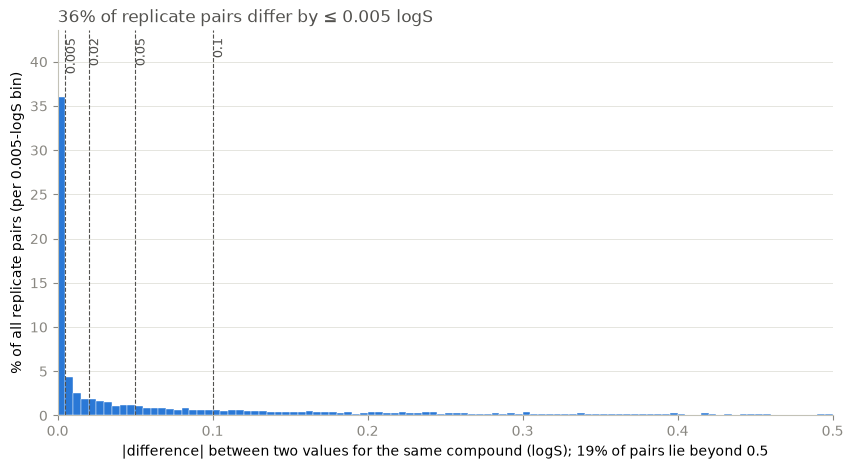

In [6]:
CUTOFFS = [0, 0.005, 0.02, 0.05, 0.1]
BAR, INK, MUTED, GRID, AXIS = "#2a78d6", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
PCT = 100 / len(pair_diffs)  # histogram weight: each pair counts as its % of all pairs


def style(ax, marks=CUTOFFS[1:]):
    """Recessive axes and grid, plus a labelled dashed line at each x in `marks` (default: the non-zero cutoffs)."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(AXIS)
    ax.tick_params(colors=MUTED)
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.set_ylim(top=ax.get_ylim()[1] * 1.15)  # headroom so cutoff labels clear the bars
    for c in marks:
        ax.axvline(c, color=INK, ls="--", lw=0.8)
        ax.text(c, 0.98, str(c), transform=ax.get_xaxis_transform(), rotation=90, color=INK, fontsize=9, va="top", ha="left")


fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(pair_diffs, bins=np.arange(0, 0.5 + 1e-9, 0.005), weights=np.full(len(pair_diffs), PCT), color=BAR, edgecolor="white", lw=0.3)
ax.set(
    xlim=(0, 0.5),
    xlabel=f"|difference| between two values for the same compound (logS); {np.mean(pair_diffs > 0.5):.0%} of pairs lie beyond 0.5",
    ylabel="% of all replicate pairs (per 0.005-logS bin)",
)
ax.set_title(f"{np.mean(pair_diffs <= 0.005):.0%} of replicate pairs differ by ≤ 0.005 logS", loc="left", color=INK)
style(ax)

The plot shows the % of replicate pairs as a function of the size of the difference. There is a huge spike around zero. That is unexpected: it implies the measurements are extremely precise, yet our data is aggregated from different sources rather than a single experiment, so it's worth interrogating. The log scale below shows the full range.

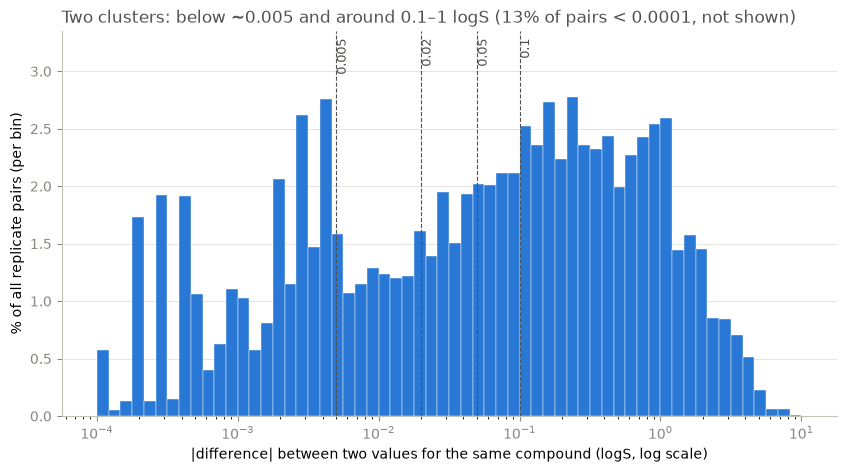

In [7]:
# Same pairs on a log x-axis (12 bins per decade, so bins widen to the right). Differences below 1e-4, including exact
# zeros, can't sit on this axis and are left out: they are effectively identical values.
shown = pair_diffs[pair_diffs >= 1e-4]
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(shown, bins=np.logspace(-4, 1, 61), weights=np.full(len(shown), PCT), color=BAR, edgecolor="white", lw=0.3)
ax.set(
    xscale="log",
    xlabel="|difference| between two values for the same compound (logS, log scale)",
    ylabel="% of all replicate pairs (per bin)",
)
ax.set_title(
    f"Two clusters: below ~0.005 and around 0.1–1 logS ({np.mean(pair_diffs < 1e-4):.0%} of pairs < 0.0001, not shown)",
    loc="left",
    color=INK,
)
style(ax)

## Can measurement noise explain the spike?

The log scale shows two clusters: a spike of pairs within about 0.005 logS of each other, and a broad hump around 0.1–1 logS. Either measurement noise has a very sharp peak and a long tail, or many near-identical pairs are not independent measurements at all. This section tests the first explanation; the next section tests the second.

Each family models the difference between two replicate values. We fit its scale twice: to the share of pairs within 0.005 logS (the spike) and to the share beyond 0.5 logS (the spread). If the spike were ordinary noise, one scale would fit both. We repeat this with one random pair per compound so compounds with many values can't dominate.

A mix of very precise and ordinary measurements could still produce a spike; the next section tests that.

In [8]:
from scipy import stats

FAMILIES = {"Gaussian": stats.norm, "Laplace": stats.laplace, "t(2)": stats.t(2), "Cauchy": stats.cauchy}
NEAR, FAR = 0.005, 0.5
one_pair = pairs.groupby("InChIKey").sample(1, random_state=0)["diff"].to_numpy()


def share_within(dist, c, scale):
    """P(|d| <= c) when the replicate difference d follows `dist` at this scale."""
    return 2 * dist.cdf(c / scale) - 1


rows, fits = [], {}
for sample, d in [("all pairs", pair_diffs), ("one pair per compound", one_pair)]:
    near, far = np.mean(d <= NEAR), np.mean(d > FAR)
    for fam, dist in FAMILIES.items():
        spike = NEAR / dist.ppf((1 + near) / 2)  # scale that reproduces the observed spike
        spread = FAR / dist.ppf(1 - far / 2)  # scale that reproduces the observed spread
        fits[sample, fam] = spike, spread
        rows.append(
            {
                "sample": sample,
                "family": fam,
                f"observed % ≤ {NEAR}": 100 * near,
                "spike-fit scale": spike,
                f"→ predicted % > {FAR}": 100 * (1 - share_within(dist, FAR, spike)),
                f"observed % > {FAR}": 100 * far,
                "spread-fit scale": spread,
                f"→ predicted % ≤ {NEAR}": 100 * share_within(dist, NEAR, spread),
            }
        )
pd.DataFrame(rows).set_index(["sample", "family"]).round(
    {f"observed % ≤ {NEAR}": 1, f"observed % > {FAR}": 1, f"→ predicted % > {FAR}": 2, f"→ predicted % ≤ {NEAR}": 2, "spike-fit scale": 4, "spread-fit scale": 3}
)

observed % ≤ 0.005  spike-fit scale  \
sample                family                                          
all pairs             Gaussian                36.1           0.0107   
                      Laplace                 36.1           0.0112   
                      t(2)                    36.1           0.0091   
                      Cauchy                  36.1           0.0079   
one pair per compound Gaussian                51.8           0.0071   
                      Laplace                 51.8           0.0068   
                      t(2)                    51.8           0.0058   
                      Cauchy                  51.8           0.0047   

                                → predicted % > 0.5  observed % > 0.5  \
sample                family                                            
all pairs             Gaussian                 0.00              18.8   
                      Laplace                  0.00              18.8   
                      t(2)                     0.03              18.8   
                      Cauchy                   1.00              18.8   
one pair per compound Gaussian                 0.00              14.2   
                      Laplace                  0.00              14.2   
                      t(2)                     0.01              14.2   
                      Cauchy                   0.60              14.2   

                                spread-fit scale  → predicted % ≤ 0.005  
sample                family                                             
all pairs             Gaussian             0.380                   1.05  
                      Laplace              0.299                   1.66  
                      t(2)                 0.254                   1.39  
                      Cauchy               0.152                   2.09  
one pair per compound Gaussian             0.340                   1.17  
                      Laplace              0.256                   1.93  
                      t(2)                 0.212                   1.67  
                      Cauchy               0.113                   2.81

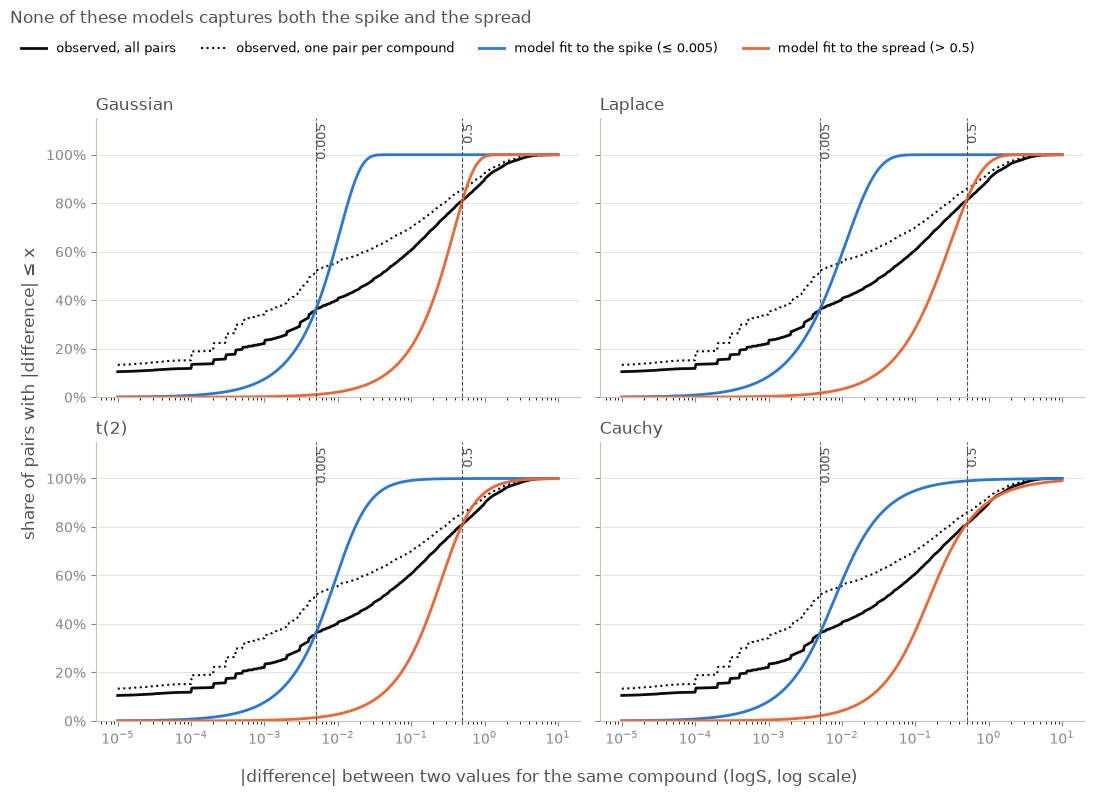

In [9]:
OBS, SERIES = "#0b0b0b", ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # observed data in ink; models in categorical order
x = np.logspace(-5, 1, 500)
ecdf = lambda d: np.searchsorted(np.sort(d), x, side="right") / len(d)

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
for ax, (fam, dist) in zip(axes.flat, FAMILIES.items()):
    spike, spread = fits["all pairs", fam]
    ax.plot(x, ecdf(pair_diffs), color=OBS, lw=2, label="observed, all pairs")
    ax.plot(x, ecdf(one_pair), color=OBS, lw=1.5, ls=":", label="observed, one pair per compound")
    ax.plot(x, share_within(dist, x, spike), color=SERIES[0], lw=2, label=f"model fit to the spike (≤ {NEAR})")
    ax.plot(x, share_within(dist, x, spread), color=SERIES[1], lw=2, label=f"model fit to the spread (> {FAR})")
    ax.set(xscale="log", ylim=(0, 1))
    ax.set_title(fam, loc="left", color=INK)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    style(ax, marks=[NEAR, FAR])
fig.supxlabel("|difference| between two values for the same compound (logS, log scale)", color=INK)
fig.supylabel("share of pairs with |difference| ≤ x", color=INK)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.01, 0.955), ncol=4, frameon=False, fontsize=9)
fig.suptitle("None of these models captures both the spike and the spread", x=0.01, ha="left", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.93))

## Does agreement depend on the source?

If near-zero pairs were very precise measurements, we'd expect a similar agreement rate whichever two compilations the values come from. If they are copies, it should vary by compilation pair. Nearly all same-source pairs are repeats within dataset A, so cross-source pairs are also shown without A.

In [10]:
pairs["near"] = pairs["diff"] <= NEAR
same = pairs["source_1"] == pairs["source_2"]
involves_a = (pairs["source_1"] == "A") | (pairs["source_2"] == "A")
groups = {
    "same source": same,
    "same source, dataset A only": same & involves_a,
    "cross source": ~same,
    "cross source, excluding A": ~same & ~involves_a,
}
pd.DataFrame({name: {"pairs": m.sum(), f"% ≤ {NEAR}": round(100 * pairs.loc[m, "near"].mean(), 1)} for name, m in groups.items()}).T.astype({"pairs": int})

,pairs,% ≤ 0.005
same source,6756,5.7
"same source, dataset A only",6521,5.1
cross source,18477,47.1
"cross source, excluding A",13386,56.7


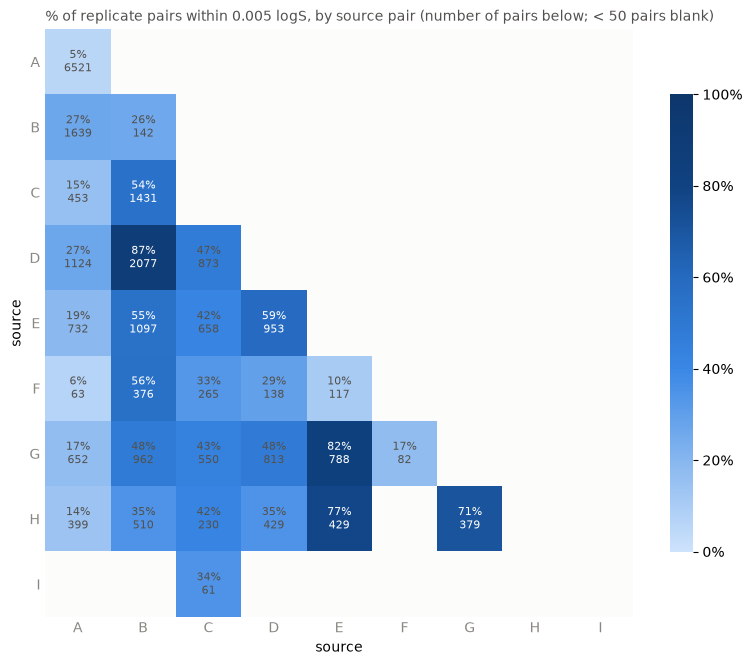

In [11]:
from matplotlib.colors import LinearSegmentedColormap

SOURCES, MIN_PAIRS = list("ABCDEFGHI"), 50  # cells with fewer pairs are left blank
lo, hi = pairs[["source_1", "source_2"]].min(axis=1), pairs[["source_1", "source_2"]].max(axis=1)
by_pair = pairs.assign(lo=lo, hi=hi).groupby(["hi", "lo"])["near"].agg(["mean", "size"])
rate = by_pair["mean"].unstack().reindex(index=SOURCES, columns=SOURCES)
count = by_pair["size"].unstack().reindex(index=SOURCES, columns=SOURCES)
rate = rate.where(count >= MIN_PAIRS)

blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"])
blues.set_bad("#fcfcfb")
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(rate.to_numpy(dtype=float), cmap=blues, vmin=0, vmax=1)
for i, j in zip(*np.where(rate.notna())):
    r = rate.iat[i, j]
    ax.text(j, i, f"{r:.0%}\n{int(count.iat[i, j])}", ha="center", va="center", fontsize=8, color="white" if r > 0.5 else INK)
ax.set(xticks=range(9), yticks=range(9), xticklabels=SOURCES, yticklabels=SOURCES, xlabel="source", ylabel="source")
ax.tick_params(colors=MUTED, length=0)
ax.spines[:].set_visible(False)
ax.set_title(f"% of replicate pairs within {NEAR} logS, by source pair (number of pairs below; < {MIN_PAIRS} pairs blank)", loc="left", fontsize=10, color=INK)
fig.colorbar(im, ax=ax, shrink=0.7, format=plt.matplotlib.ticker.PercentFormatter(1)).outline.set_visible(False)
fig.tight_layout()

Near-zero agreement depends strongly on the source pair (5% within dataset A, up to 88% between some compilations), and none of the four noise models fits the spike and the spread together. On this evidence, our judgement is that most near-zero pairs are the same value copied between compilations, not independent measurements. Copies would shrink Var(noise) and make the data look more precise than it is, so we merge them before estimating it. That raises the next question: how close must two values be to count as one?

## Choosing a cutoff

Merging also catches genuine pairs that happen to agree closely, so some real signal is lost. We estimate how many with two references, which we treat as rough bounds:

- **Fitted models (likely low).** Each family is fitted only to pairs with |d| > C0, assuming no copies there; the best fit per C0 is projected inward. The fits miss the shape between ~0.02 and 0.6, so they likely under-count genuine pairs near zero.
- **Dataset A's own repeats (likely high).** The lowest near-zero rate of any source pair, used as the shape of genuine differences. Some A–A pairs are copies too, so it over-counts.

Minimizing genuine merges alone would pick cutoff 0. So the rule is two-sided: keep raising the cutoff while the pairs newly merged by each increase are mostly copies.

In [12]:
from scipy.optimize import minimize_scalar

C0S = [0.05, 0.1, 0.2]


def fit_beyond(dist, c0):
    """Max-likelihood scale for |d| using only pairs with |d| > c0 (truncated fit).

    Returns (scale, log-likelihood, genuine pairs implied overall = pairs beyond c0 / P(|d| > c0)).
    """
    x = pair_diffs[pair_diffs > c0]
    nll = lambda log_s: -(dist.logpdf(x / np.exp(log_s)).sum() - len(x) * (log_s + dist.logsf(c0 / np.exp(log_s))))
    log_s = minimize_scalar(nll, bounds=(np.log(1e-3), np.log(10)), method="bounded").x
    return np.exp(log_s), -nll(log_s), len(x) / (2 * dist.sf(c0 / np.exp(log_s)))


genuine = pd.DataFrame(
    [
        {"C0": c0, "family": fam, **dict(zip(["scale", "log-likelihood", "genuine pairs"], fit_beyond(dist, c0)))}
        for c0 in C0S
        for fam, dist in FAMILIES.items()
    ]
)
genuine["best fit"] = genuine.index.isin(genuine.groupby("C0")["log-likelihood"].idxmax())
best = genuine[genuine["best fit"]].set_index("C0")

# Empirical reference: dataset A's within-source repeats, sized to match pairs beyond 0.1 (assumes no copies there).
aa = pair_diffs[(pairs["source_1"] == "A") & (pairs["source_2"] == "A")]
aa_genuine = (pair_diffs > 0.1).sum() / np.mean(aa > 0.1)
genuine.set_index(["C0", "family"]).round({"scale": 3, "log-likelihood": 1, "genuine pairs": 0})

scale  log-likelihood  genuine pairs  best fit
C0   family                                                  
0.05 Gaussian  1.140         -9908.5        12228.0     False
     Laplace   0.655         -6807.4        12736.0     False
     t(2)      0.435         -6469.7        12841.0     False
     Cauchy    0.272         -6215.9        13344.0      True
0.10 Gaussian  1.224         -8880.5        10610.0     False
     Laplace   0.725         -6728.3        11386.0     False
     t(2)      0.509         -6528.0        11502.0      True
     Cauchy    0.321         -6571.3        12279.0     False
0.20 Gaussian  1.349         -7426.6         8715.0     False
     Laplace   0.823         -6187.1         9804.0     False
     t(2)      0.616         -6111.7         9905.0      True
     Cauchy    0.384         -6404.4        11071.0     False

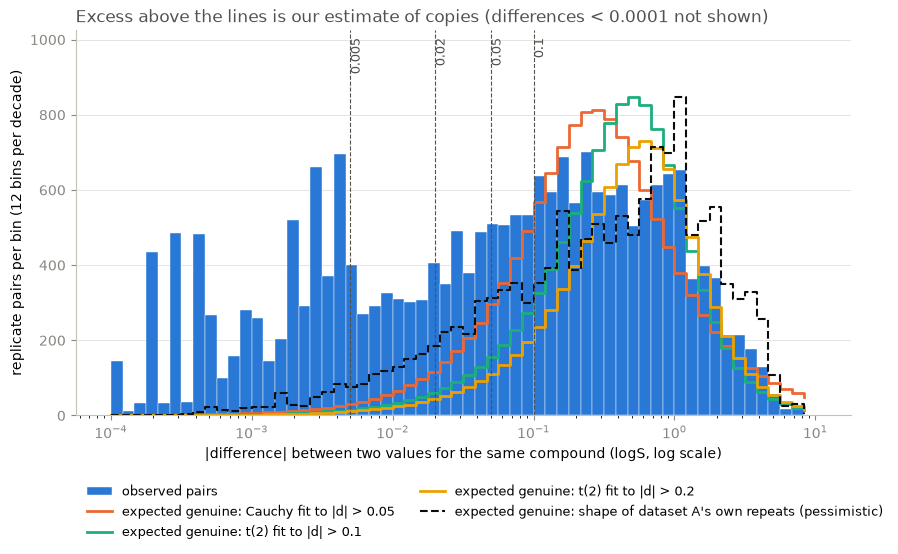

In [13]:
edges = np.logspace(-4, 1, 61)
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(pair_diffs, bins=edges, color=BAR, edgecolor="white", lw=0.3, label="observed pairs")
for color, (c0, fit) in zip(SERIES[1:], best.iterrows()):
    dist = FAMILIES[fit["family"]]
    expected = fit["genuine pairs"] * np.diff(share_within(dist, edges, fit["scale"]))
    ax.step(edges[:-1], expected, where="post", color=color, lw=2, label=f"expected genuine: {fit['family']} fit to |d| > {c0}")
ax.step(edges[:-1], aa_genuine * np.histogram(aa, edges)[0] / len(aa), where="post", color=OBS, lw=1.5, ls="--",
        label="expected genuine: shape of dataset A's own repeats (pessimistic)")
ax.set(xscale="log", xlabel="|difference| between two values for the same compound (logS, log scale)", ylabel="replicate pairs per bin (12 bins per decade)")
ax.set_title("Excess above the lines is our estimate of copies (differences < 0.0001 not shown)", loc="left", color=INK)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.15), ncol=2, frameon=False, fontsize=9)
style(ax)

In [14]:
expected = pd.DataFrame(
    {
        **{
            f"{fit['family']} fit, C0={c0}": fit["genuine pairs"] * share_within(FAMILIES[fit["family"]], np.array(CUTOFFS), fit["scale"])
            for c0, fit in best.iterrows()
        },
        "dataset A repeats": [aa_genuine * np.mean(aa <= c) for c in CUTOFFS],
    },
    index=pd.Index(CUTOFFS, name="cutoff (logS)"),
)
merged = pd.Series([(pair_diffs <= c).sum() for c in CUTOFFS], index=expected.index)
genuine_share = expected.div(merged, axis=0)  # of everything merged at this cutoff
# Raising the cutoff from the previous row to this one merges `newly_merged` more pairs; what share of them are copies?
# (The first row compares against no merging at all.)
newly_merged = merged.diff().fillna(merged).astype(int)
step_copy_share = 1 - expected.diff().fillna(expected).div(newly_merged, axis=0)


def span(df, decimals):
    """min-max across the estimates, as a percent range per row."""
    return [f"{100 * lo:.{decimals}f}–{100 * hi:.{decimals}f}" if pd.notna(lo) else "" for lo, hi in zip(df.min(axis=1), df.max(axis=1))]


pd.DataFrame(
    {
        "pairs merged": merged,
        **expected.round().astype(int).add_prefix("genuine merged: "),
        "% genuine, all merged pairs": span(genuine_share, 1),
        "newly merged vs previous cutoff": newly_merged,
        "% copies, newly merged pairs": span(step_copy_share, 0),
    }
)

,pairs merged,"genuine merged: Cauchy fit, C0=0.05","genuine merged: t(2) fit, C0=0.1","genuine merged: t(2) fit, C0=0.2",genuine merged: dataset A repeats,"% genuine, all merged pairs",newly merged vs previous cutoff,"% copies, newly merged pairs"
cutoff (logS),,,,,,,,
0.000,2578,0,0,0,224,0.0–8.7,2578,91–100
0.005,9097,156,80,57,708,0.6–7.8,6519,93–99
0.020,11313,623,320,227,1616,2.0–14.3,2216,59–92
0.050,13433,1544,797,568,2818,4.2–21.0,2120,43–84
0.100,15314,2992,1583,1130,3979,7.4–26.0,1881,23–70


Up to 0.02, every estimate says the newly merged pairs are mostly copies (59–92% when going from 0.005 to 0.02). Going from 0.02 to 0.05, the dataset A reference says the newly merged pairs are mostly genuine (44% copies). The cutoff is a judgement on this evidence: lower merges fewer genuine pairs, higher catches more copies.

## Votes, gross errors and consensus

The cutoff analysis above located the copies: essentially everything within 0.02 logS, and most of the 0.02–0.1 band. Rather than pick one cutoff and pool a single variance over whatever survives — which blurs three different populations into one number — each population now gets its own treatment:

- **Copies vote once.** Within a compound, values within δ = 0.1 logS of each other (single linkage) form one *vote*: one independent measurement, however many compilations reprinted it, entering as the cluster's mean. Sensitivity runs at δ = 0.05 and 0.15 bracket the band where that cutoff analysis could not fully separate copies from genuine agreement.
- **Gross errors are flagged, never deleted.** Among compounds with 3+ votes, a vote more than T = 1.5 logS from the median of the others is flagged. 1.5 logS is where the known error mechanisms live — a mg/mL-for-mg/L slip is exactly 3 logS, a wrong salt or crystal form 1.5–3 — and the hump of ordinary disagreement seen earlier has died away by there; T = 1.2 and 2.0 show the sensitivity. Compounds with exactly two votes that disagree by more than T are *unresolved*: neither value can be blamed, so neither is flagged and the pair is counted separately.
- **What remains is genuine noise**, estimated below without assuming any distribution family.

The consensus is the median of a compound's unflagged votes. Compounds with a single vote get no consensus check at all; they carry the flagged-error rate as a prior probability that their one label is junk.

In [15]:
DELTA, THRESHOLD = 0.1, 1.5  # primary setting (our choice); the grid shows the sensitivity to both
DELTAS, THRESHOLDS = [0.05, 0.1, 0.15], [1.2, 1.5, 2.0]

by_compound = src.groupby("InChIKey")[TARGET].apply(np.array)


def votes_of(values: np.ndarray, delta: float) -> np.ndarray:
    """One vote per copy cluster: single-linkage at `delta` over a compound's sorted values, each cluster's mean."""
    values = np.sort(values)
    return np.array([c.mean() for c in np.split(values, np.flatnonzero(np.diff(values) > delta) + 1)])


def flag_errors(votes: np.ndarray, threshold: float) -> np.ndarray:
    """True where a vote lies further than `threshold` from the median of the other unflagged votes (3+ votes).

    Rounds update every flag at once: updating one vote at a time lets the median drift and cascade through one
    side of a split population. Majority guard: a consensus needs a strict majority, so if half or more of the
    votes would be flagged, the compound has no consensus and nothing is flagged.
    """
    flags = np.zeros(len(votes), bool)
    for _ in range(3):
        others = lambda k: votes[~flags & (np.arange(len(votes)) != k)]
        new = np.array([abs(v - np.median(others(k))) > threshold if len(others(k)) >= 2 else flags[k] for k, v in enumerate(votes)])
        if new.sum() * 2 >= len(votes):
            return np.zeros(len(votes), bool)
        if (new == flags).all():
            break
        flags = new
    return flags


def analyze(delta: float, threshold: float) -> dict:
    """Votes, flags, consensus and noise residuals for every compound at one (delta, threshold) setting."""
    votes = {key: votes_of(g, delta) for key, g in by_compound.items()}
    flags = {key: flag_errors(w, threshold) if len(w) >= 3 else np.zeros(len(w), bool) for key, w in votes.items()}
    consensus = {key: float(np.median(w[~flags[key]])) for key, w in votes.items()}
    residuals = np.array([  # unflagged votes around the mean of the compound's other unflagged votes, unit leverage
        (good[k] - np.delete(good, k).mean()) * np.sqrt((len(good) - 1) / len(good))
        for key, w in votes.items()
        for good in [w[~flags[key]]]
        if len(good) >= 3
        for k in range(len(good))
    ])
    flagged_dev = np.array([x - consensus[key] for key, w in votes.items() for x in w[flags[key]]])
    n3 = sum(len(w) for w in votes.values() if len(w) >= 3)
    two = [w for w in votes.values() if len(w) == 2]
    unresolved = int(sum(abs(w[0] - w[1]) > threshold for w in two))
    flagged = int(sum(f.sum() for f in flags.values()))
    return {
        "votes": votes, "flags": flags, "consensus": consensus, "residuals": residuals, "flagged_dev": flagged_dev,
        "stats": {
            "votes in 3+-vote compounds": n3,
            "flagged": flagged,
            "error rate (3+ votes)": flagged / n3,
            "2-vote compounds": len(two),
            "2-vote disagreeing > T": unresolved,
            "error rate incl. 2-vote": (flagged + unresolved) / (n3 + 2 * len(two)),
            "noise SD (robust, logS)": 1.4826 * float(np.median(np.abs(residuals))),
        },
    }


RESULTS = {(d, t): analyze(d, t) for d in DELTAS for t in THRESHOLDS}
A = RESULTS[DELTA, THRESHOLD]
print(
    f"at δ={DELTA}: {sum(len(w) for w in A['votes'].values())} votes over {len(A['votes'])} compounds; "
    f"{sum(len(w) == 1 for w in A['votes'].values())} compounds have a single vote and carry the error rate as a prior"
)
pd.DataFrame({f"δ={d}, T={t}": r["stats"] for (d, t), r in RESULTS.items()}).T.round(
    {"error rate (3+ votes)": 3, "error rate incl. 2-vote": 3, "noise SD (robust, logS)": 3}
)

at δ=0.1: 12097 votes over 9946 compounds; 8366 compounds have a single vote and carry the error rate as a prior


,votes in 3+-vote compounds,flagged,error rate (3+ votes),2-vote compounds,2-vote disagreeing > T,error rate incl. 2-vote,"noise SD (robust, logS)"
"δ=0.05, T=1.2",1877.0,115.0,0.061,1330.0,193.0,0.068,0.394
"δ=0.05, T=1.5",1877.0,93.0,0.050,1330.0,146.0,0.053,0.401
"δ=0.05, T=2.0",1877.0,75.0,0.040,1330.0,86.0,0.035,0.417
"δ=0.1, T=1.2",1273.0,99.0,0.078,1229.0,200.0,0.080,0.593
"δ=0.1, T=1.5",1273.0,84.0,0.066,1229.0,150.0,0.063,0.589
"δ=0.1, T=2.0",1273.0,65.0,0.051,1229.0,89.0,0.041,0.623
"δ=0.15, T=1.2",966.0,70.0,0.072,1112.0,210.0,0.088,0.760
"δ=0.15, T=1.5",966.0,59.0,0.061,1112.0,159.0,0.068,0.760
"δ=0.15, T=2.0",966.0,52.0,0.054,1112.0,92.0,0.045,0.760


In [16]:
# The strongest flags, and a check that what gets caught is what the mechanisms predict.
names = src.drop_duplicates("InChIKey").set_index("InChIKey")["Name"].astype(str)
offenders = sorted(
    ((key, w[A["flags"][key]], A["consensus"][key]) for key, w in A["votes"].items() if A["flags"][key].any()),
    key=lambda t: -np.abs(t[1] - t[2]).max(),
)
print(f"{len(offenders)} compounds carry a flag at δ={DELTA}, T={THRESHOLD}; the 12 furthest from consensus:")
display(pd.DataFrame(
    {
        "consensus (logS)": [round(c, 2) for _, _, c in offenders[:12]],
        "flagged votes (logS)": [", ".join(f"{x:.2f}" for x in bad) for _, bad, _ in offenders[:12]],
    },
    index=[names[k][:55] for k, *_ in offenders[:12]],
))
all_names = src.groupby("InChIKey")["Name"].agg(lambda s: " / ".join(map(str, s)).lower())
for probe in ["warfarin", "ciprofloxacin", "but-2-enedioic"]:
    for key, bad, c in offenders:
        if probe in all_names[key]:
            print(f"{probe}: consensus {c:.2f}, flagged {np.round(bad, 2)}")
            break

65 compounds carry a flag at δ=0.1, T=1.5; the 12 furthest from consensus:


,consensus (logS),flagged votes (logS)
aluminium(3+) ion dichloride hydroxide,-6.69,0.88
dicopper(2+) ion chloride trihydroxide,-5.54,"-0.55, -0.33"
"6-({bis[(5-carboxypentyl)amino]-1,3,5-triazin-2-yl}amin",-2.15,-6.39
cobalt,-5.13,"-8.77, -8.47, -8.29, -8.17, -7.87"
2-(4-methylcyclohex-3-en-1-yl)propan-2-ol,-1.89,-5.49
4-hydroxy-3-(3-oxo-1-phenylbutyl)-2H-chromen-2-one,-4.26,-0.67
Aluminum;phosphenic acid,-4.15,"-7.29, -6.88"
cobalt sulphide,-4.93,"-6.69, -1.87"
"2-(1,3-benzothiazol-2-yldisulfanyl)-1,3-benzothiazole",-3.83,-6.82
silicon,-5.79,-2.80


warfarin: consensus -4.26, flagged [-0.67]
ciprofloxacin: consensus -3.68, flagged [-1.04]


Across the grid, 4–8% of independent measurements are flagged as gross errors. At the primary setting it is about 7% of the votes in 3+-vote compounds, and the flagged votes sit a median of ~2 logS from their compound's consensus — the scale of unit slips and wrong forms, not of ordinary disagreement. The flags catch exactly the predicted mechanisms: warfarin's −0.67 against a −4.26 consensus (a mg/mL-for-mg/L slip is 3 logS, and warfarin *sodium* is about that soluble), ciprofloxacin's −1.04, and sparingly soluble inorganics whose "solubility" is genuinely ill-defined. The majority guard also catches an identity ambiguity the stereo ruling predicted: but-2-enedioic acid, drawn without E/Z marks, holds values whose own row names say (2E)- (fumaric, −1.22) and (2Z)- (maleic, 0.83) — two compounds under one under-specified structure — and the guard declares no consensus rather than picking a side. Flags are recorded, never deleted: every vote keeps its row.

Two pieces of honest accounting. Two-vote compounds that disagree by more than T are *unresolved* — neither value can be blamed — and enter the combined rate. And the compounds with a single vote cannot be checked at all: they carry the error rate as a prior, which predicts that several hundred of them hold a wrong label that no model of the structure can fix. Downstream, those will look like compounds every model gets wrong.

## The floor, recomputed without a family

The goal cell's formula assumes Gaussian noise with a single variance. Earlier, no simple family fit the replicate differences, and the previous section explains why: "the noise" was three populations blurred together — copies, genuine disagreement, and gross errors. With copies collapsed into votes and errors flagged, the genuine noise can speak for itself. Its density comes straight from the data: the residuals of unflagged votes around the mean of their compound's other unflagged votes (compounds with ≥ 3 good votes; each residual scaled by $\sqrt{(K-1)/K}$ so its variance matches a single measurement's), smoothed with a kernel density estimate and symmetrized. The floor is then computed numerically, with no family assumed:

$$I(\mu; Y) \;=\; h(Y) - h(e)$$

where $h(e)$ is the differential entropy of the noise density and $h(Y)$ that of the consensus values convolved with it. Two versions matter: a **typical measurement** (gross errors removed) and a **label as it arrives** (the error rate mixed back in at the flagged-deviation scale). Both are shown across the copy band δ and the threshold T.

In [17]:
def floor_bits(residuals: np.ndarray, consensus: np.ndarray, error_rate: float = 0.0, error_sd: float = 2.4,
               step: float = 0.01, half: float = 30.0) -> float:
    """I(mu; Y) = h(Y) - h(e) in bits. The noise density comes from the residuals (symmetrized KDE), mixed with a
    wide error component at `error_rate`; h(Y) is the entropy of the consensus values convolved with that noise."""
    grid = np.arange(-half, half + step, step)
    fe = stats.gaussian_kde(np.concatenate([residuals, -residuals]))(grid)
    fe = (1 - error_rate) * fe / (fe.sum() * step) + error_rate * stats.norm.pdf(grid, 0, error_sd)
    h_e = -np.sum(fe[fe > 0] * np.log2(fe[fe > 0])) * step
    hist = np.bincount(((consensus - consensus.min()) / step).astype(int)) / (len(consensus) * step)
    fy = np.convolve(hist, fe) * step
    h_y = -np.sum(fy[fy > 0] * np.log2(fy[fy > 0])) * step
    return h_y - h_e


floors = pd.DataFrame(
    {
        f"δ={d}, T={t}": {
            "typical measurement (bits)": floor_bits(r["residuals"], np.array(list(r["consensus"].values()))),
            "label as it arrives (bits)": floor_bits(
                r["residuals"], np.array(list(r["consensus"].values())),
                error_rate=r["stats"]["error rate incl. 2-vote"],
                error_sd=max(float(np.std(r["flagged_dev"])) if len(r["flagged_dev"]) else 2.4, 1.5),
            ),
        }
        for (d, t), r in RESULTS.items()
    }
).T
floors["levels, typical (2^bits)"] = 2 ** floors["typical measurement (bits)"]
display(floors.round(2))

# Bootstrap at the primary setting: resample compounds, recompute residuals, error rate and consensus, re-floor.
rng = np.random.default_rng(0)
keys_list = list(A["votes"])
good_by_key = {key: A["votes"][key][~A["flags"][key]] for key in keys_list}
res_by_key = {
    key: [(g[k] - np.delete(g, k).mean()) * np.sqrt((len(g) - 1) / len(g)) for k in range(len(g))] if len(g) >= 3 else []
    for key, g in good_by_key.items()
}
boot = []
for _ in range(100):
    pick = rng.integers(len(keys_list), size=len(keys_list))
    res = np.array([r for p in pick for r in res_by_key[keys_list[p]]])
    n3 = sum(len(A["votes"][keys_list[p]]) for p in pick if len(A["votes"][keys_list[p]]) >= 3)
    flagged = sum(A["flags"][keys_list[p]].sum() for p in pick)
    mu = np.array([A["consensus"][keys_list[p]] for p in pick])
    boot.append((flagged / n3, floor_bits(res, mu)))
rate_b, floor_b = np.array(boot).T
print(
    f"primary (δ={DELTA}, T={THRESHOLD}): typical floor "
    f"{floor_bits(A['residuals'], np.array(list(A['consensus'].values()))):.2f} bits "
    f"(bootstrap {np.percentile(floor_b, 2.5):.2f}–{np.percentile(floor_b, 97.5):.2f}); "
    f"error rate {A['stats']['error rate (3+ votes)']:.1%} "
    f"(bootstrap {np.percentile(rate_b, 2.5):.1%}–{np.percentile(rate_b, 97.5):.1%})"
)

# For scale: the goal cell's formula on these same votes (Gaussian noise, one pooled variance), with the flagged
# votes inside and then removed. The gap between the two is what gross errors do to a pooled variance, which weights
# a 2-logS error quadratically; the gap from there to the distribution-free floor above is the Gaussian assumption.
def pooled_formula(votes_by_compound: list[np.ndarray]) -> tuple[float, float]:
    kept = [w for w in votes_by_compound if len(w) > 1]
    within = sum(((w - w.mean()) ** 2).sum() for w in kept) / sum(len(w) - 1 for w in kept)
    return 0.5 * np.log2(np.var(np.concatenate(votes_by_compound), ddof=1) / within), float(np.sqrt(within))


for label, by in [("all votes", list(A["votes"].values())), ("flagged votes removed", [w[~A["flags"][k]] for k, w in A["votes"].items()])]:
    bits, sd = pooled_formula(by)
    print(f"goal-cell formula, {label}: pooled SD {sd:.3f} logS -> {bits:.2f} bits")


,typical measurement (bits),label as it arrives (bits),"levels, typical (2^bits)"
"δ=0.05, T=1.2",1.93,1.76,3.81
"δ=0.05, T=1.5",1.92,1.77,3.77
"δ=0.05, T=2.0",1.94,1.81,3.82
"δ=0.1, T=1.2",1.53,1.40,2.90
"δ=0.1, T=1.5",1.56,1.43,2.94
"δ=0.1, T=2.0",1.59,1.48,3.00
"δ=0.15, T=1.2",1.26,1.18,2.39
"δ=0.15, T=1.5",1.29,1.21,2.44
"δ=0.15, T=2.0",1.36,1.27,2.57


primary (δ=0.1, T=1.5): typical floor 1.56 bits (bootstrap 1.42–1.67); error rate 6.6% (bootstrap 5.1%–8.2%)
goal-cell formula, all votes: pooled SD 0.927 logS -> 1.38 bits
goal-cell formula, flagged votes removed: pooled SD 0.844 logS -> 1.51 bits


At the primary setting a typical genuine measurement carries about **1.5–1.6 bits** about its compound's consensus solubility, and 1.3–1.9 bits across the grid — the spread over δ is the honest remaining uncertainty about where copies end. A label as it arrives carries ~0.1 bits less: the price of a ~6% chance of being junk. The printed comparison shows what each simplification would cost: the goal cell's formula on the same votes gives about 1.4 bits with the flagged votes inside and 1.5 with them removed — 84 votes, under 1% of the total, move a pooled *variance* by more than a tenth of a bit because it weights a 2-logS error quadratically — and the Gaussian assumption accounts for the remaining gap to the distribution-free value. (A latent mixture fitted to the same residuals is not identifiable here — the scales form a continuum, and it relabels ordinary between-source disagreement as "error" — which is why the threshold is explicit instead.)

The floor is now a diagnostic, not a design input: [02_tiers.ipynb](02_tiers.ipynb) will choose the number of tiers directly on held-out votes. The cell below hands it one row per independent measurement.

In [18]:
# Hand-off: one row per independent measurement (vote) at the primary setting. A vote is a copy cluster: its value
# is the cluster mean, its metadata the member row nearest that mean, and its flag marks a likely gross error.
rows = []
for key, d in src.sort_values(TARGET, kind="stable").groupby("InChIKey"):
    w, f = A["votes"][key], A["flags"][key]
    parts = np.split(np.arange(len(d)), np.flatnonzero(np.diff(d[TARGET].to_numpy()) > DELTA) + 1)
    assert len(parts) == len(w), f"{key}: vote clustering disagrees with the hand-off split"
    for vote, flag, part in zip(w, f, parts):
        rep = d.iloc[part[np.argmin(np.abs(d[TARGET].to_numpy()[part] - vote))]]
        rows.append({
            "ID": rep["ID"], "Name": rep["Name"], "InChIKey": key, "SMILES": rep["SMILES"],
            "sources": "".join(sorted(set(d["source"].to_numpy()[part]))), "n_copies": len(part),
            TARGET: vote, "votes_in_compound": len(w), "flagged": bool(flag), "consensus": A["consensus"][key],
        })
measurements = pd.DataFrame(rows)
assert len(measurements) == sum(len(w) for w in A["votes"].values())
measurements.to_csv(ROOT / "data" / "aqsoldb_measurements.csv", index=False)
print(
    f"{len(measurements)} independent measurements for {measurements['InChIKey'].nunique()} compounds, "
    f"{int(measurements['flagged'].sum())} flagged -> data/aqsoldb_measurements.csv"
)

12097 independent measurements for 9946 compounds, 84 flagged -> data/aqsoldb_measurements.csv
